# 2. Hype cycles in the mean-field model

With a media campaign that rises and then fades, expectations $m_1$ overshoot the technology's realised
value, fall when media attention recedes faster than performance improves, and recover as performance
catches up: peak, trough, plateau. Adoption follows an S-curve driven by the share of non-users whose
perceived value exceeds the price.

Default inputs: media frequency $\mu(t)=e^{-(t-2)^2/2}$, message $w(t)$ rising to 1.5 at $t=2$ and flat
afterwards, constant price $P=1$, exogenous investment $I_{\rm exo}(t)=0.1\,t$.

peak 0.879 at t=1.68;  trough 0.729 at t=4.23;  final 0.800;  adoption at t=20: 0.74


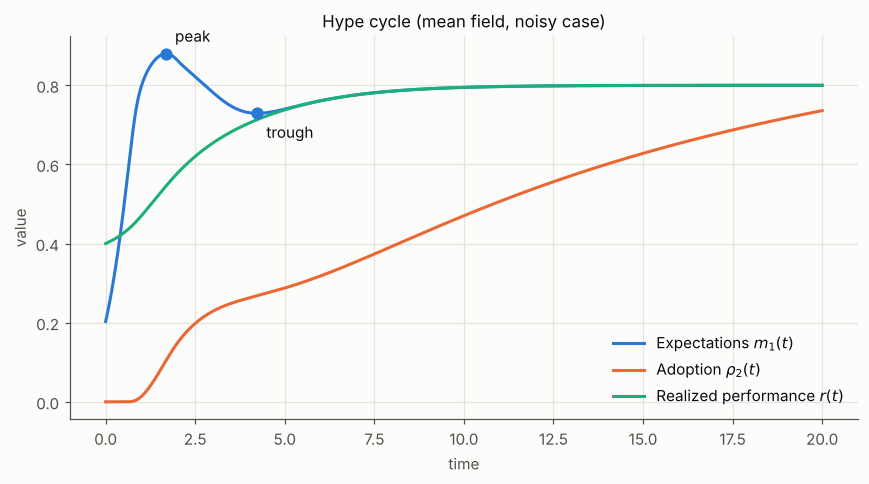

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kinetic_hype import Params, Signals, gaussian, linear, meanfield as mf, hype_features
from kinetic_hype.plotting import use_style, plot_trajectory, QUANTITY, INK_2

use_style()
p, s = Params(), Signals()
d = mf.simulate(p, s, T=20)
f = hype_features(d)

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_trajectory(ax, d)
for t_, y_, lab in [(f.t_peak, f.peak, "peak"), (f.t_trough, f.trough, "trough")]:
    ax.plot(t_, y_, "o", color=QUANTITY["m1"]["color"], ms=7)
    ax.annotate(lab, (t_, y_), textcoords="offset points", xytext=(6, 8 if lab == "peak" else -16))
ax.set_ylabel("value"); ax.set_title("Hype cycle (mean field, noisy case)")
ax.legend(loc="lower right")
fig.tight_layout()
print(f"peak {f.peak:.3f} at t={f.t_peak:.2f};  trough {f.trough:.3f} at t={f.t_trough:.2f};  "
      f"final {f.final:.3f};  adoption at t=20: {d.rho.iloc[-1]:.2f}")

## Why the noise matters

With no self-reasoning noise ($\gamma=0$) everyone shares the same perceived value and the hazard is an
on/off switch: purchases happen only while $m_1>P$. Expectations climb to the price, adoption starts, and
users' reports (bounded by $r_\infty=0.8<P$) pull $m_1$ back below the price, so adoption stops at a few
per cent. With noise, part of the population stays above the price and adoption continues.

adoption at t=20: deterministic 0.082, noisy 0.736


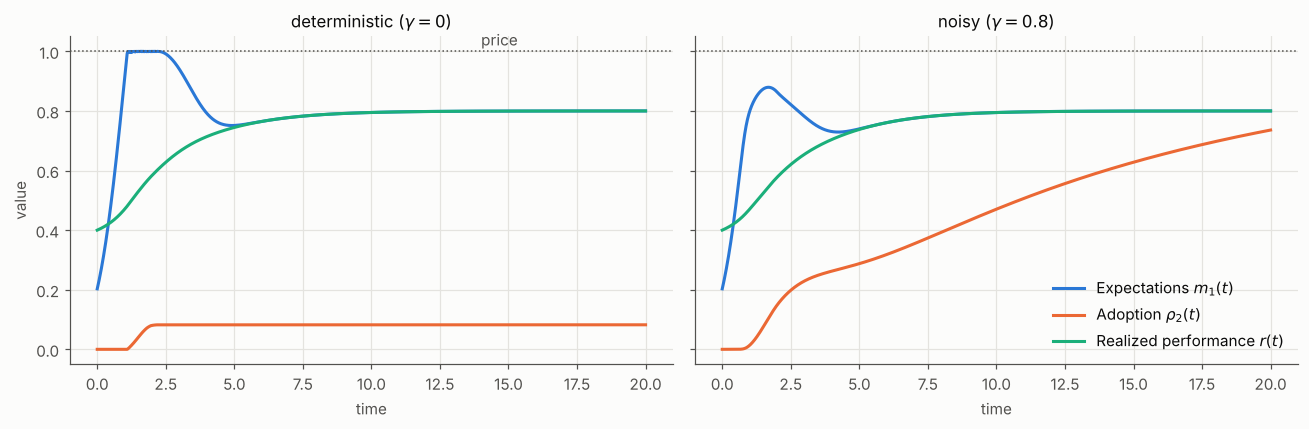

In [2]:
det = mf.simulate(Params(gam=0.0), s, T=20)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
plot_trajectory(axes[0], det); axes[0].set_title(r"deterministic ($\gamma = 0$)")
plot_trajectory(axes[1], d); axes[1].set_title(r"noisy ($\gamma = 0.8$)")
axes[0].axhline(1.0, color=INK_2, ls=":", lw=1); axes[1].axhline(1.0, color=INK_2, ls=":", lw=1)
axes[0].text(14, 1.02, "price", color=INK_2)
axes[0].set_ylabel("value"); axes[1].legend(loc="lower right")
fig.tight_layout()
print(f"adoption at t=20: deterministic {det.rho.iloc[-1]:.3f}, noisy {d.rho.iloc[-1]:.3f}")

## What shapes the cycle

Two levers: how quickly media attention fades (the width of the Gaussian bump) and how much exogenous
investment drives performance. Each panel varies one and keeps the rest at the defaults.

,varied,value,peak,t_peak,trough,t_trough,adoption_t20,hype_cycle
0,media width^2,0.5,0.896,1.79,0.673,3.30,0.717,True
1,media width^2,2.0,0.879,1.68,0.729,4.23,0.736,True
2,media width^2,8.0,0.876,1.60,0.782,6.15,0.764,True
3,media width^2,32.0,0.876,1.56,0.800,16.75,0.803,False
4,investment slope,0.0,0.871,1.66,0.688,4.31,0.697,True
5,investment slope,0.1,0.879,1.68,0.729,4.23,0.736,True
6,investment slope,0.3,0.897,1.73,0.775,4.34,0.773,True


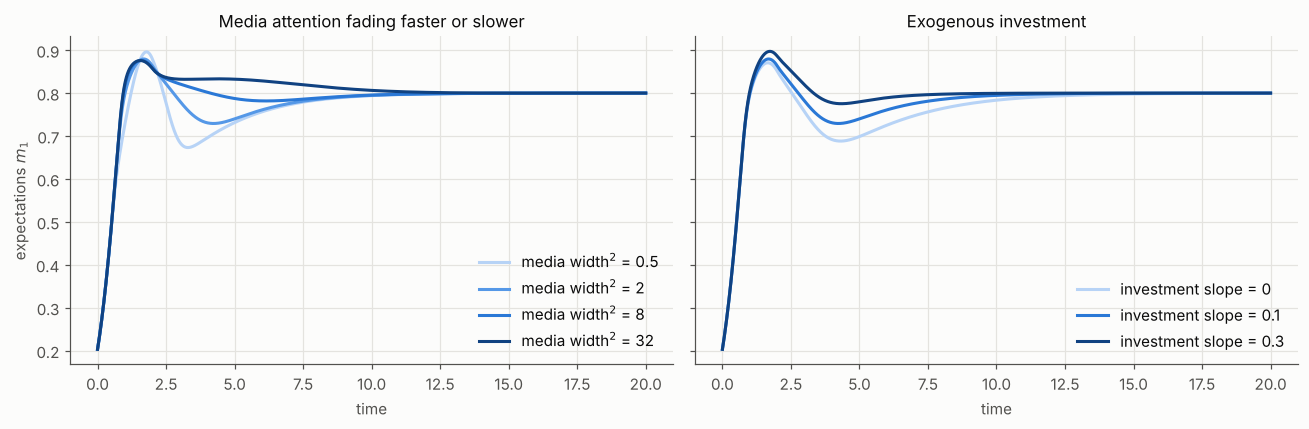

In [3]:
widths = [0.5, 2.0, 8.0, 32.0]
slopes = [0.0, 0.1, 0.3]
shades4 = ["#b7d3f6", "#5598e7", "#2a78d6", "#104281"]
shades3 = ["#b7d3f6", "#2a78d6", "#104281"]
rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for w2, c in zip(widths, shades4):
    run = mf.simulate(p, Signals(media=gaussian(2.0, w2)), T=20)
    axes[0].plot(run.t, run.m1, color=c, label=f"media width$^2$ = {w2:g}")
    h = hype_features(run)
    rows.append({"varied": "media width^2", "value": w2, "peak": h.peak, "t_peak": h.t_peak,
                 "trough": h.trough, "t_trough": h.t_trough, "adoption_t20": run.rho.iloc[-1],
                 "hype_cycle": h.is_hype_cycle(t_min=0.1)})
for sl, c in zip(slopes, shades3):
    run = mf.simulate(p, Signals(investment=linear(sl)), T=20)
    axes[1].plot(run.t, run.m1, color=c, label=f"investment slope = {sl:g}")
    h = hype_features(run)
    rows.append({"varied": "investment slope", "value": sl, "peak": h.peak, "t_peak": h.t_peak,
                 "trough": h.trough, "t_trough": h.t_trough, "adoption_t20": run.rho.iloc[-1],
                 "hype_cycle": h.is_hype_cycle(t_min=0.1)})
axes[0].set_title("Media attention fading faster or slower"); axes[1].set_title("Exogenous investment")
for ax in axes: ax.set_xlabel("time"); ax.legend(loc="lower right")
axes[0].set_ylabel(r"expectations $m_1$")
fig.tight_layout()
pd.DataFrame(rows).round(3)

**Reading the table.** The trough exists because media attention recedes before performance has caught up.
When attention fades slowly (width$^2$ = 32) expectations glide down to the plateau without undershooting, so
there is no cycle by the criterion used here (a drop of at least 0.02 followed by a recovery of at least
0.01). Faster performance growth, via exogenous investment, makes the trough shallower and adoption
higher. These are illustrations at one parameter set; notebook 5 maps the whole parameter space.